<a href="https://colab.research.google.com/github/sandiya200567-cloud/cassava-leaf-disease-recognition/blob/main/RA2311026050246_PS06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install tensorflow-datasets scikit-learn seaborn importlib-resources

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names
num_classes = info.features["label"].num_classes

print("Class names:", class_names)
print("Number of classes:", num_classes)
print("Training images:", info.splits["train"].num_examples)
print("Validation images:", info.splits["validation"].num_examples)
print("Test images:", info.splits["test"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Class names: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Number of classes: 5
Training images: 5656
Validation images: 1889
Test images: 1885


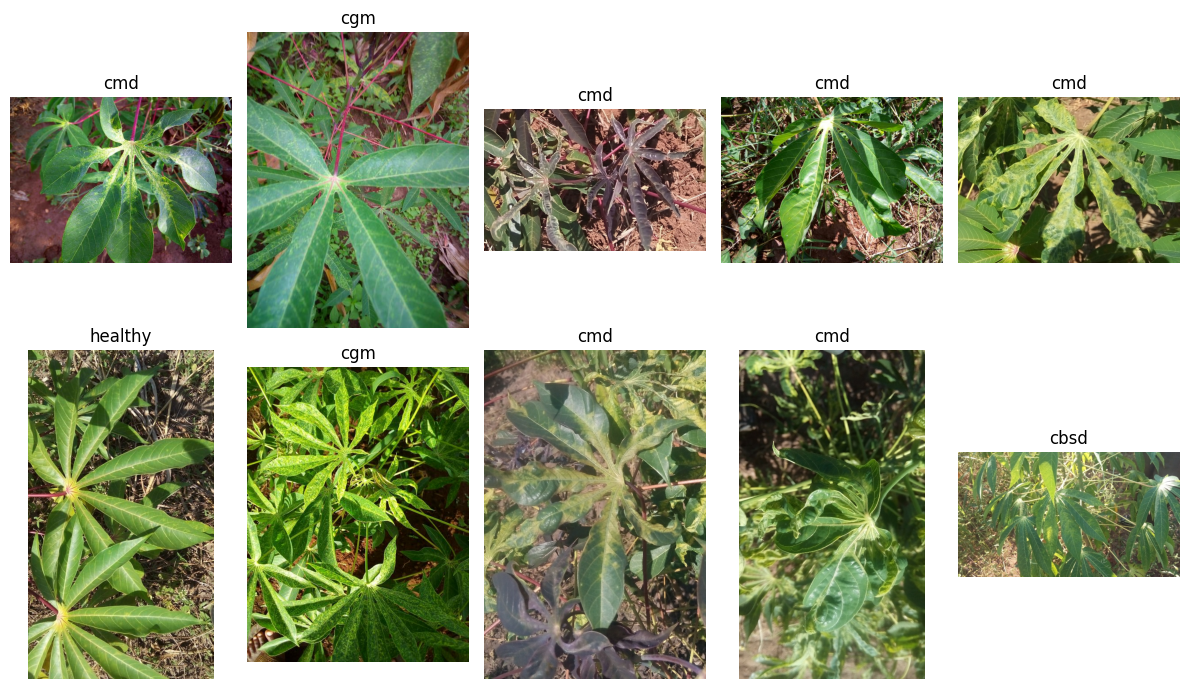

In [ ]:
plt.figure(figsize=(12, 7))

for i, (image, label) in enumerate(ds_train.take(10)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[int(label.numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

,Class,Training Images
0,cbb,466
1,cbsd,1443
2,cgm,773
3,cmd,2658
4,healthy,316


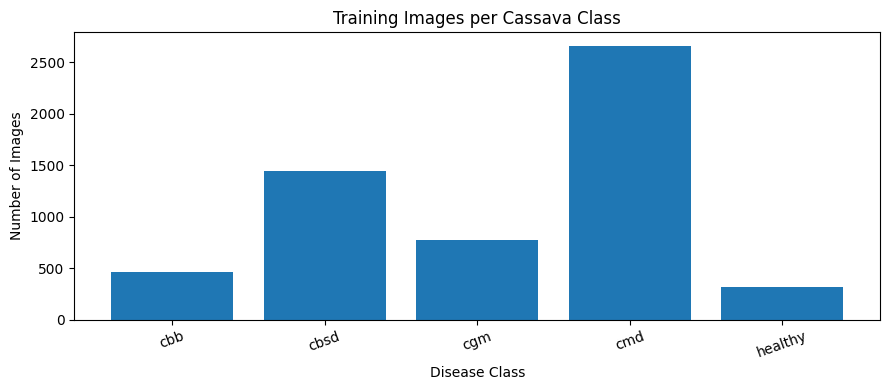

In [ ]:
# Count training images in each class
train_counts = np.zeros(num_classes, dtype=int)

for _, label in tfds.as_numpy(ds_train):
    train_counts[int(label)] += 1

# Create the table
counts_df = pd.DataFrame({
    "Class": class_names,
    "Training Images": train_counts
})

display(counts_df)

# Plot class distribution
plt.figure(figsize=(9, 4))
plt.bar(counts_df["Class"], counts_df["Training Images"])
plt.title("Training Images per Cassava Class")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def resize_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label

train_ds = (
    ds_train
    .map(resize_image, num_parallel_calls=AUTOTUNE)
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    ds_val
    .map(resize_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    ds_test
    .map(resize_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Image pipeline ready!")

Image pipeline ready!


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name="augmentation")

base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6
    )
]

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

training_minutes = (time.time() - start_time) / 60
print(f"Training time: {training_minutes:.2f} minutes")

Epoch 1/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 34s 122ms/step - accuracy: 0.5826 - loss: 1.0966 - val_accuracy: 0.6818 - val_loss: 0.8655 - learning_rate: 0.0010
Epoch 2/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - accuracy: 0.6701 - loss: 0.8609 - val_accuracy: 0.6945 - val_loss: 0.8096 - learning_rate: 0.0010
Epoch 3/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 41s 111ms/step - accuracy: 0.6917 - loss: 0.8070 - val_accuracy: 0.7104 - val_loss: 0.7849 - learning_rate: 0.0010
Epoch 4/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - accuracy: 0.7049 - loss: 0.7814 - val_accuracy: 0.7210 - val_loss: 0.7671 - learning_rate: 0.0010
Epoch 5/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 22s 111ms/step - accuracy: 0.7152 - loss: 0.7571 - val_accuracy: 0.7051 - val_loss: 0.8001 - learning_rate: 0.0010
Epoch 6/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 41s 111ms/step - accuracy: 0.7224 - loss: 0.7384 - val_accuracy: 0.7316 - val_loss: 0.7373 - learning_rate: 5.0000e-04
Epoch 7/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 41s 112ms/step - accuracy: 0.7270

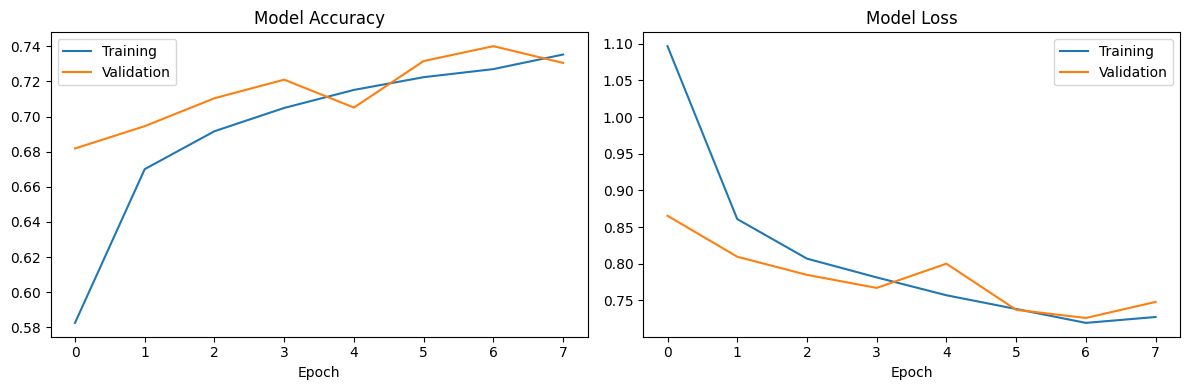

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

59/59 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step
Test Accuracy: 0.7369
Macro F1: 0.6426

Per-class results:
              precision    recall  f1-score   support

         cbb     0.4176    0.4903    0.4510       155
        cbsd     0.7573    0.6486    0.6988       481
         cgm     0.7211    0.5310    0.6116       258
         cmd     0.8548    0.8770    0.8657       886
     healthy     0.4531    0.8286    0.5859       105

    accuracy                         0.7369      1885
   macro avg     0.6408    0.6751    0.6426      1885
weighted avg     0.7533    0.7369    0.7387      1885



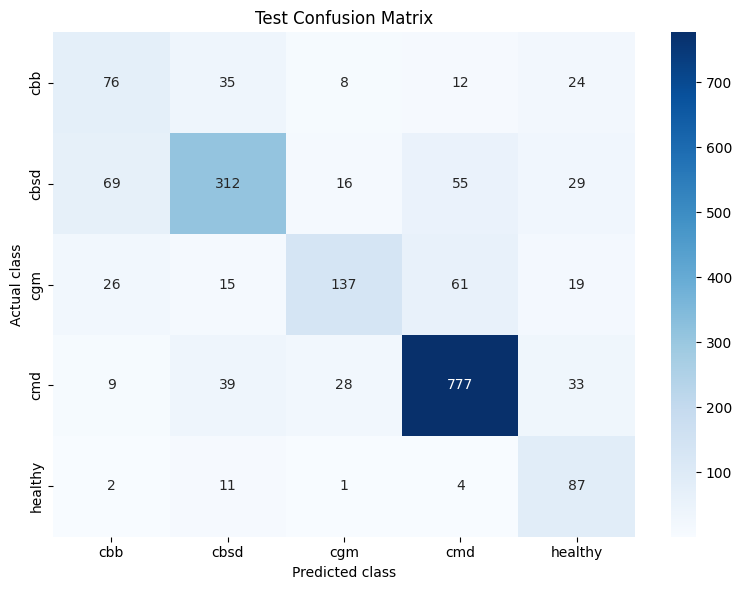

In [ ]:
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f}")

print("\nPer-class results:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
model.save("cassava_disease_model.keras")
print("Model saved successfully")

Model saved successfully


In [ ]:
from google.colab import files
files.download("cassava_disease_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Misclassified test images: 496


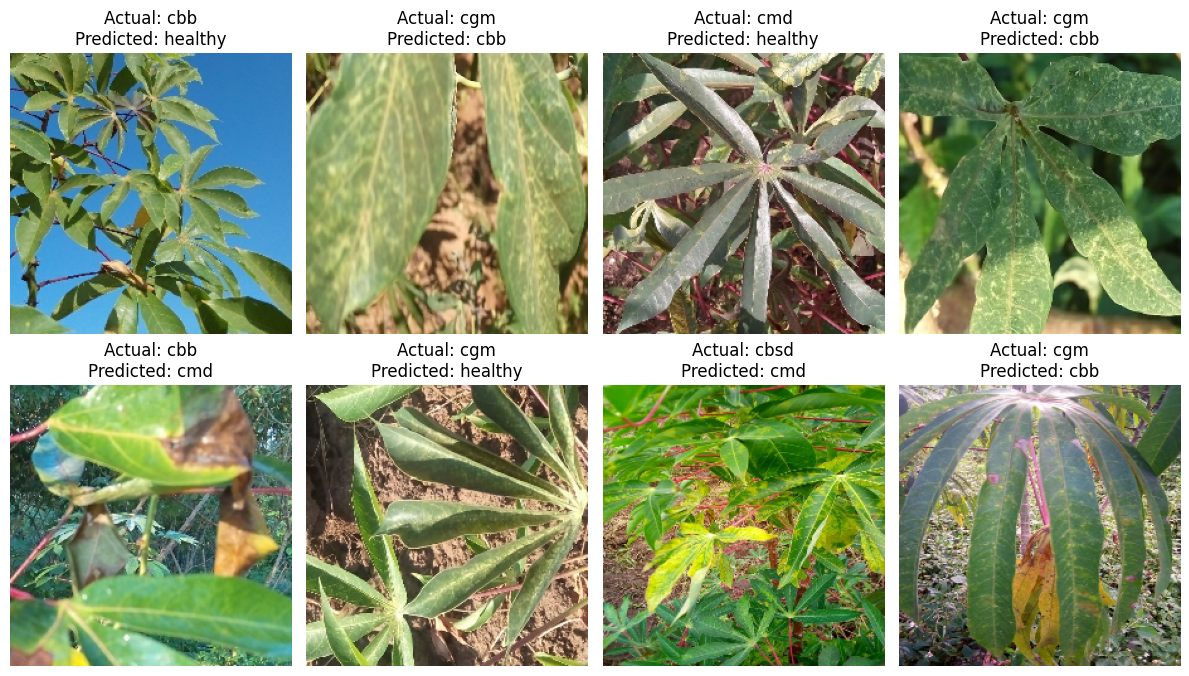

In [ ]:
wrong_indices = np.where(y_true != y_pred)[0]

print("Misclassified test images:", len(wrong_indices))

plt.figure(figsize=(12, 7))

for plot_i, idx in enumerate(wrong_indices[:8]):
    batch_idx = idx // BATCH_SIZE
    image_idx = idx % BATCH_SIZE

    batch_images, _ = next(iter(test_ds.skip(batch_idx).take(1)))
    image = batch_images[image_idx].numpy()

    plt.subplot(2, 4, plot_i + 1)
    plt.imshow(np.clip(image / 255.0, 0, 1))
    plt.title(
        f"Actual: {class_names[y_true[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()